<a href="https://colab.research.google.com/github/dughilamiruna/PMP-2026/blob/main/materiale/modele.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Retele Bayesiene(DAG) cu pgmpy, VariableElimnation, d-separation**

A smart home system monitors and controls heating, cooling, and energy usage based on environmental and behavioral factors. The Bayesian network models the relationships between outside
temperature, heating system status, window status, room temperature, energy consumption, and
occupant comfort.
Variables and Domains:

● OutsideTemp (𝑂): {cold, mild}
● HeatingOn (𝐻): {yes, no}
● WindowOpen (𝑊 ): {yes, no}
● RoomTemp (𝑅): {warm, cool}
● EnergyUse (𝐸): {high, low}
● Comfort (𝐶): {comfortable, uncomfortable}

Conditional Probability Tables (CPTs):

𝑃(𝑂 = cold) = 0.3, 𝑃(𝑂 = mild) = 0.7
𝑃(𝐻 = yes ∣ 𝑂 = cold) = 0.9, 𝑃(𝐻 = yes ∣ 𝑂 = mild) = 0.2
𝑃(𝑊 = yes ∣ 𝑂 = cold) = 0.1, 𝑃(𝑊 = yes ∣ 𝑂 = mild) = 0.6
𝑃(𝑅 = warm ∣ 𝐻 = yes,𝑊 = yes) = 0.6, 𝑃(𝑅 = warm ∣ 𝐻 = yes,𝑊 = no) = 0.9
𝑃(𝑅 = warm ∣ 𝐻 = no,𝑊 = yes) = 0.3, 𝑃(𝑅 = warm ∣ 𝐻 = no,𝑊 = no) = 0.5
𝑃(𝐸 = high ∣ 𝐻 = yes) = 0.8, 𝑃(𝐸 = high ∣ 𝐻 = no) = 0.2
𝑃(𝐶 = comfortable ∣ 𝑅 = warm) = 0.85, 𝑃(𝐶 = comfortable ∣ 𝑅 = cool) = 0.40

a) Build the Bayesian network (including graph) in pgmpy.


In [2]:
!pip install pgmpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 64.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pgmpy]


In [3]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
import networkx as nx
import matplotlib.pyplot as plt

/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


In [4]:
# 1. Definirea structurii DAG
smart_home = DiscreteBayesianNetwork ([
('O', 'H'), ('O', 'W'),
('H', 'R'), ('W', 'R'),
('H', 'E'), ('R', 'C')
])

In [5]:
# 2. Definirea CPT
cpd_O = TabularCPD (
variable='O', variable_card =2,
values =[[0.3] , [0.7]] ,
state_names ={'O': ['cold', 'mild']}
)
cpd_H = TabularCPD (
variable='H', variable_card =2,
values =[[0.9 , 0.2] , # H = yes | O = cold , mild
[0.1 , 0.8]] , # H = no | O = cold , mild
evidence =['O'], evidence_card =[2] ,
state_names ={'H': ['yes', 'no'], 'O': ['cold', 'mild']}
)
cpd_W = TabularCPD (
variable='W', variable_card =2,
values =[[0.1 , 0.6] , # W = yes | O = cold , mild
[0.9 , 0.4]] , # W = no | O = cold , mild
evidence =['O'], evidence_card =[2] ,
state_names ={'W': ['yes', 'no'], 'O': ['cold', 'mild']}
)

In [6]:
# Ordinea coloanelor pentru evidence=['H', 'W']:
# (yes, yes), (yes, no), (no, yes), (no, no)
cpd_R = TabularCPD (
variable='R', variable_card =2,
values =[[0.6 , 0.9, 0.3, 0.5] , # R = warm
[0.4 , 0.1, 0.7, 0.5]] , # R = cool
evidence =['H', 'W'], evidence_card =[2, 2],
state_names ={'R': ['warm', 'cool'], 'H': ['yes', 'no'], 'W': ['yes', 'no']}
)
cpd_E = TabularCPD (
variable='E', variable_card =2,
values =[[0.8 , 0.2] , # E = high | H = yes, no
[0.2 , 0.8]] , # E = low | H = yes, no
evidence =['H'], evidence_card =[2] ,
state_names ={'E': ['high', 'low'], 'H': ['yes', 'no']}
)
cpd_C = TabularCPD (
variable='C', variable_card =2,
values =[[0.85 , 0.40] , # C = comfortable | R = warm , cool
[0.15 , 0.60]] , # C = uncomfortable | R = warm , cool
evidence =['R'], evidence_card =[2] ,
state_names ={'C': ['comfortable', 'uncomfortable'], 'R': ['warm', 'cool']}
)

In [7]:
#Adaugare si verificare
smart_home .add_cpds(cpd_O , cpd_H , cpd_W , cpd_R , cpd_E , cpd_C)
assert smart_home . check_model (), "Modelul Smart Home nu este valid!"

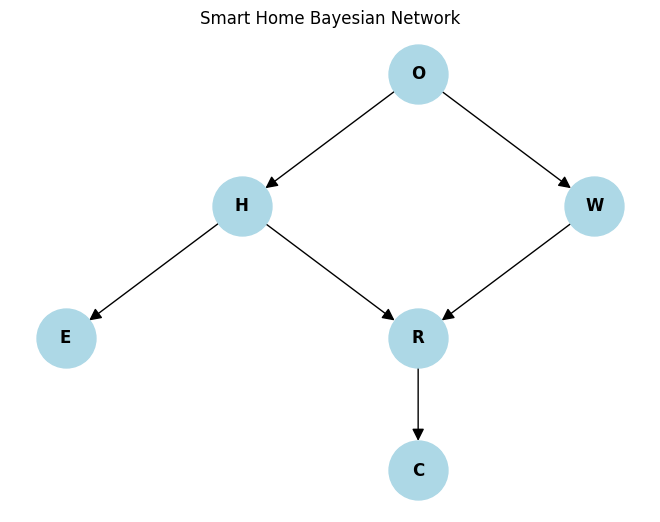

In [8]:
# 3. Vizualizarea grafului
pos = {'O': (1, 3), 'H': (0, 2), 'W': (2, 2),
'E': (-1, 1), 'R': (1, 1), 'C': (1, 0)}
nx.draw(smart_home , pos=pos , with_labels =True , node_size =1800 ,
node_color ='lightblue', arrowsize =18, font_weight ='bold')
plt.title("Smart Home Bayesian Network")
plt.show ()

b) Perform inference using VariableElimination:

● Compute 𝑃(𝐻 = yes ∣ 𝐶 = comfortable).
● Compute 𝑃(𝐸 = high ∣ 𝐶 = comfortable).
● Find the MAP estimate (greatest probability) for (𝐻,𝑊 ) given 𝐶 = comfortable.

In [9]:
infer = VariableElimination ( smart_home )

In [10]:
# 1. P(H = yes | C = comfortable)
q_H = infer.query(variables =['H'], evidence ={'C': 'comfortable'})
print("P(H | C = comfortable):\n", q_H)

# 2. P(E = high | C = comfortable)
q_E = infer.query(variables =['E'], evidence ={'C': 'comfortable'})
print("\nP(E | C = comfortable):\n", q_E)

P(H | C = comfortable):
 +--------+----------+
| H      |   phi(H) |
+========+==========+
| H(yes) |   0.4823 |
+--------+----------+
| H(no)  |   0.5177 |
+--------+----------+

P(E | C = comfortable):
 +---------+----------+
| E       |   phi(E) |
+=========+==========+
| E(high) |   0.4894 |
+---------+----------+
| E(low)  |   0.5106 |
+---------+----------+


In [11]:
# 3. MAP pentru (H, W) | C = comfortable
q_HW = infer.query(variables =['H', 'W'], evidence ={'C': 'comfortable'})
print("\nP(H, W | C = comfortable):\n", q_HW)

map_HW = infer.map_query (variables =['H', 'W'], evidence ={'C': 'comfortable'})
print("\nMAP (H, W) | C = comfortable:", map_HW)


P(H, W | C = comfortable):
 +--------+--------+------------+
| H      | W      |   phi(H,W) |
+========+========+============+
| H(yes) | W(yes) |     0.1138 |
+--------+--------+------------+
| H(yes) | W(no)  |     0.3684 |
+--------+--------+------------+
| H(no)  | W(yes) |     0.2776 |
+--------+--------+------------+
| H(no)  | W(no)  |     0.2401 |
+--------+--------+------------+


  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]


MAP (H, W) | C = comfortable: {'W': 'no', 'H': 'yes'}


c) Independence reasoning:

● Is 𝑊 ⊥ 𝐸 ∣ 𝐻? Explain using d-separation.
● Are 𝑂 and 𝐶 independent given 𝑅? Justify.

In [12]:
print("W independent de E dat fiind H?", not smart_home.is_dconnected ('W', 'E',
observed =['H']))
print("O independent de C dat fiind R?", not smart_home.is_dconnected ('O', 'C',
observed =['R']))

W independent de E dat fiind H? True
O independent de C dat fiind R? True


**HMM, Algoritmul Forward, Viterbi**

A fitness app predicts a user’s activity (hidden state) based on sensor readings (observations).
The user’s activity can be either Walking (W), Running (R) or Resting (S). The app receives sensor
observations about heart rate and step count, which are simplified into three categories: Low (L),
Medium (M) and High (H).
The system is modeled as a Hidden Markov Model (HMM) with the following model parameters:

● Initial state probabilities:
𝑃(𝑊 ) = 0.4, 𝑃(𝑅) = 0.3, 𝑃(𝑆) = 0.3

● Transition probabilities:
𝑃(𝑊 ∣𝑊 ) = 0.6, 𝑃(𝑅∣𝑊 ) = 0.3, 𝑃(𝑆∣𝑊 ) = 0.1
𝑃(𝑊 ∣𝑅) = 0.2, 𝑃(𝑅∣𝑅) = 0.7, 𝑃(𝑆∣𝑅) = 0.1
𝑃(𝑊 ∣𝑆) = 0.3, 𝑃(𝑅∣𝑆) = 0.2, 𝑃(𝑆∣𝑆) = 0.5

● Emission probabilities:
𝑃(𝐿∣𝑊 ) = 0.1, 𝑃(𝑀∣𝑊 ) = 0.7, 𝑃(𝐻∣𝑊 ) = 0.2
𝑃(𝐿∣𝑅) = 0.05, 𝑃(𝑀∣𝑅) = 0.25, 𝑃(𝐻∣𝑅) = 0.7
𝑃(𝐿∣𝑆) = 0.8, 𝑃(𝑀∣𝑆) = 0.15, 𝑃(𝐻∣𝑆) = 0.05

a) Model Construction: Define the HMM using hmmlearn (or any suitable library). Specify the
initial, transition, and emission probabilities.

In [13]:
!pip install hmmlearn

In [14]:
import numpy as np
from hmmlearn import hmm

In [20]:
# Definirea modelului HMM
# Stari ascunse (3): 0 = Walking (W), 1 = Running (R), 2 = Resting (S)
# Observatii: 0 = Low (L), 1 = Medium (M), 2 = High (H)
states = ['Walking', 'Running', 'Resting']
obs_names = {'L': 0, 'M': 1, 'H': 2}
model = hmm. CategoricalHMM ( n_components =3)
model. n_features = 3

model. startprob_ = np.array ([0.4 , 0.3, 0.3])
model. transmat_ = np.array ([
[0.6 , 0.3, 0.1] , # din W
[0.2 , 0.7, 0.1] , # din R
[0.3 , 0.2, 0.5] # din S
])
model. emissionprob_ = np.array ([
[0.10 , 0.70 , 0.20] , # W -> L, M, H
[0.05 , 0.25 , 0.70] , # R -> L, M, H
[0.80 , 0.15 , 0.05] # S -> L, M, H
])

b) Forward Algorithm: Compute the probability of observing the sequence:
Observations = [Medium, High, Low]

In [21]:
# Secventa tinta: [Medium , High , Low] -> [1, 2, 0]
obs_seq = np.array ([[ obs_names ['M']], [ obs_names ['H']], [ obs_names ['L']]])

In [22]:
# Algoritmul Forward: P(O = [M, H, L])
log_prob_forward = model.score(obs_seq)
prob_forward = np.exp( log_prob_forward )
print(f"b) Probabilitate exacta Forward P([M, H, L]) = {prob_forward:.6f}")

b) Probabilitate exacta Forward P([M, H, L]) = 0.021117


c) Viterbi Algorithm: Find the most likely sequence of hidden states for the same observation
sequence.

In [23]:
# Algoritmul Viterbi
log_prob_viterbi , best_path_idx = model.decode(obs_seq , algorithm ="viterbi")
best_path = [states[i] for i in best_path_idx ]
print(f"c) Secventa Viterbi optima: {best_path}")
print(f" Probabilitatea comuna P(S*, O) = {np.exp(log_prob_viterbi):.6f}")

c) Secventa Viterbi optima: ['Walking', 'Running', 'Resting']
 Probabilitatea comuna P(S*, O) = 0.004704


d) Generate 10,000 sequences using the HMM and estimate the empirical probability of the
observation sequence [𝑀, 𝐻, 𝐿]. Compare with the exact probability from the Forward algorithm.

In [24]:
N_sim = 10000
target = np.array ([1, 2, 0])
matches = 0

for _ in range(N_sim):
  X_sim , _ = model.sample( n_samples =3)
  if np. array_equal (X_sim.ravel (), target):
    matches += 1

prob_empirica = matches / N_sim
print(f"d) Probabilitate empirica ({N_sim} simulari) = {prob_empirica:.6f}")
print(f"Diferenta absoluta fata de Forward = {abs(prob_empirica - prob_forward
):.6f}")

d) Probabilitate empirica (10000 simulari) = 0.021500
Diferenta absoluta fata de Forward = 0.000383
